In [5]:

import torch
import torch.nn.functional as F
from entmax import entmax_bisect
from torch.nn.utils.rnn import pad_sequence
from transformers import (
    AutoTokenizer,
    Qwen3_5ForConditionalGeneration,
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen3.5-4B"

DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

DTYPE = (
    torch.bfloat16 if DEVICE != "cpu"
    else torch.float32
)

ALPHA = 1.85
TOKEN_ALPHA = ALPHA
BETA = 5
TOKEN_BETA = BETA
HOPFIELD_STEPS = 4
TOL = 1e-6

LAYER_FRACTION = 0.2
MAX_NEW_TOKENS = 120

texts = [
    "Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.",
    "An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.",
    "Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.",
    "Esmorzar de forquilla is a similar concept of brunch in Catalonia. Normally stews and meat dishes are served.",
    "Sunny and warm weather make people happier.",
    "Rainy and cold weather can negatively affect people's mood.",
    "People tend to spend more time outdoors when the weather is pleasant.",
    'Paella is a traditional Valencian dish. The original version is called "Paella Valenciana".',
]

query_text = "What are the main ingredients of Fricandó? Where is it from?"

print("QUERY TEXT:", query_text)

# ============================================================
# 2. LOAD MODEL
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = Qwen3_5ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
).to(DEVICE).eval()

tokenizer.padding_side = "left"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

layers = model.model.language_model.layers

num_layers = len(layers)

layer_idx = min(
    int(num_layers * LAYER_FRACTION),
    num_layers - 1,
)

print("Model:", type(model).__name__)
print("Device:", DEVICE)
print("Number of layers:", num_layers)
print("Selected layer:", layer_idx)


# ============================================================
# 3. EXTRACT FULL CONTEXTUAL TOKEN REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_representations(texts, layer_idx):
    """
    Extract complete contextual representations at a
    selected transformer layer.

    Each sentence is encoded independently to avoid
    padding effects.

    Returns:
        full_sequences: list of [Li, D]
            Original, unnormalized contextual token states.
    """
    full_sequences = []

    for text in texts:
        encoded = tokenizer(
            text,
            return_tensors="pt",
            add_special_tokens=False,
        ).to(DEVICE)

        captured = []

        def capture_hook(module, args, output):
            hidden = (
                output[0]
                if isinstance(output, tuple)
                else output
            )
            captured.append(hidden.detach())

        handle = layers[layer_idx].register_forward_hook(
            capture_hook
        )

        try:
            model(
                **encoded,
                use_cache=False,
                return_dict=True,
            )
        finally:
            handle.remove()

        if len(captured) != 1:
            raise RuntimeError(
                f"Expected one capture, got {len(captured)}"
            )

        # [1, Li, D] -> [Li, D]
        hidden = captured[0].squeeze(0)

        # Save every token, preserving original magnitudes
        full_sequences.append(hidden.clone())

    return full_sequences


# ============================================================
# 4. BUILD MEMORY BANK
# ============================================================

memory_sequences = extract_representations(
    texts,
    layer_idx,
)

memories = pad_sequence(
    memory_sequences,
    batch_first=True,
    padding_value=0.0,
)

memory_mask = (
        torch.arange(memories.shape[1], device=memories.device)[None, :]
        < torch.tensor(
    [seq.shape[0] for seq in memory_sequences],
    device=memories.device,
)[:, None]
)

query = extract_representations(
    [query_text],
    layer_idx,
)[0]

print("\nMEMORY BANK")
print("Sentence vectors:", memories.shape)
print("Query vector:", query.shape)
print("Memory mask:", memory_mask.shape)


# ============================================================
# 5. HOPFIELD-FENCHEL-YOUNG RETRIEVAL
# ============================================================


def hopfield_late_interaction(
        query: torch.Tensor,  # [Sq, D]
        memories: torch.Tensor,  # [N, Sm, D]
        alpha: float = 1.85,
        beta: float = 5.0,
        steps: int = 4,
        tol: float = 1e-6,
        token_alpha: float = 1.85,
        token_beta: float = 5.0,
        memory_mask: torch.Tensor | None = None,  # [N, Sm]
):
    # --------------------------------------------------------
    # 1. Validate inputs
    # --------------------------------------------------------

    if not 1.0 <= alpha <= 2.0:
        raise ValueError("alpha must be in [1, 2]")

    if not 1.0 <= token_alpha <= 2.0:
        raise ValueError("token_alpha must be in [1, 2]")

    if query.ndim != 2:
        raise ValueError("Expected query [Sq, D]")

    if memories.ndim != 3:
        raise ValueError("Expected memories [N, Sm, D]")

    if query.shape[-1] != memories.shape[-1]:
        raise ValueError("Embedding dimension mismatch")

    if steps < 1:
        raise ValueError("steps must be >= 1")

    if beta <= 0 or token_beta <= 0:
        raise ValueError("beta values must be positive")

    # --------------------------------------------------------
    # 2. Prepare memory keys and values
    # --------------------------------------------------------

    # ORIGINAL states: used for reconstruction.
    M_values = memories.float()

    # NORMALIZED states: used only for cosine similarity.
    M_keys = F.normalize(M_values, dim=-1)

    # Preserve original query magnitudes.
    state = query.float().clone()

    if memory_mask is not None:
        if memory_mask.shape != memories.shape[:2]:
            raise ValueError("Invalid memory_mask shape")

        memory_mask = memory_mask.to(
            device=memories.device,
            dtype=torch.bool,
        )

        if not memory_mask.any(dim=-1).all():
            raise ValueError(
                "Every memory needs at least one valid token"
            )

    trajectory = [state.clone()]

    # --------------------------------------------------------
    # 3. Entmax helper
    # --------------------------------------------------------

    def entmax(scores, alpha_value, dim):
        if alpha_value == 1.0:
            return F.softmax(scores, dim=dim)

        return entmax_bisect(
            scores,
            alpha=alpha_value,
            dim=dim,
            n_iter=50,
        )

    # --------------------------------------------------------
    # 4. Late-interaction retrieval
    # --------------------------------------------------------

    def retrieve(current_state):

        # Normalize query only for similarity.
        Q_keys = F.normalize(current_state, dim=-1)

        # Cosine similarity between all query and memory tokens.
        #
        # [Sq, D] @ [N, D, Sm] -> [N, Sq, Sm]
        similarity = torch.matmul(
            Q_keys,
            M_keys.transpose(1, 2),
        )

        # Exclude padded memory tokens.
        if memory_mask is not None:
            similarity = similarity.masked_fill(
                ~memory_mask[:, None, :],
                float("-inf"),
            )

        # ----------------------------------------------------
        # Sentence-level retrieval (MaxSim)
        # ----------------------------------------------------

        # Best matching memory token for each query token.
        # [N, Sq]
        max_similarity = similarity.max(dim=-1).values

        # Aggregate across query tokens.
        # [N]
        scores = max_similarity.mean(dim=-1)

        # Sparse sentence-level weights.
        # [N]
        weights = entmax(
            beta * scores,
            alpha,
            dim=0,
        )

        # ----------------------------------------------------
        # Token-level alignment
        # ----------------------------------------------------

        # For each query token, distribute weights over the
        # memory tokens of each sentence.
        # [N, Sq, Sm]
        alignment = entmax(
            token_beta * similarity,
            token_alpha,
            dim=-1,
        )

        # ----------------------------------------------------
        # Reconstruct ORIGINAL hidden states
        # ----------------------------------------------------

        # [N, Sq, Sm] @ [N, Sm, D] -> [N, Sq, D]
        aligned = torch.bmm(
            alignment,
            M_values,
        )

        # Combine aligned sequences using sentence weights.
        #
        # [N, 1, 1] * [N, Sq, D] -> [N, Sq, D]
        # Sum over N -> [Sq, D]
        new_state = (
                weights[:, None, None] * aligned
        ).sum(dim=0)

        return new_state, weights, alignment

    # --------------------------------------------------------
    # 5. Iterative retrieval
    # --------------------------------------------------------

    for _ in range(steps):

        new_state, _, _ = retrieve(state)

        delta = torch.linalg.vector_norm(
            new_state - state
        )

        state = new_state

        trajectory.append(state.clone())

        if delta.item() < tol:
            break

    # Recompute weights for final retrieved state.
    _, weights, alignment = retrieve(state)

    return (
        state,
        weights,
        alignment,
        torch.stack(trajectory),
    )


with torch.no_grad():
    retrieved_state, weights, alignment, trajectory = hopfield_late_interaction(
        query,
        memories,
        alpha=ALPHA,
        token_alpha=TOKEN_ALPHA,
        beta=BETA,
        token_beta=TOKEN_BETA,
        steps=HOPFIELD_STEPS,
        tol=TOL,
        memory_mask=memory_mask,
    )

print("\nHFY RETRIEVAL")

for i in torch.argsort(weights, descending=True).tolist():
    print(f"{weights[i].item():.6f} | {texts[i]}")

print("Iterations:", len(trajectory) - 1)

# ============================================================
# 6. INJECT FULL WEIGHTED TOKEN MEMORY
# ============================================================


from contextlib import contextmanager
import torch


@contextmanager
def prepend_memory_at_layer(
        layer_idx: int,
        memory_tokens: torch.Tensor,  # [M, D] or [1, M, D]
        memory_scale: float = 1.0,
):
    """
    Replace reserved prefix positions after layer_idx.

    Designed for full-sequence forwards with use_cache=False.
    Batch size 1 only.
    """
    if memory_tokens.ndim == 2:
        memory_tokens = memory_tokens.unsqueeze(0)

    if memory_tokens.ndim != 3 or memory_tokens.shape[0] != 1:
        raise ValueError("Expected memory_tokens [1, M, D]")

    calls = 0

    def hook(module, args, output):
        nonlocal calls

        hidden = output[0] if isinstance(output, tuple) else output

        memory = memory_tokens.detach().to(
            device=hidden.device,
            dtype=hidden.dtype,
        ) * memory_scale

        B, M, D = memory.shape

        if hidden.shape[0] != B:
            raise ValueError("Batch size mismatch")

        if hidden.shape[1] <= M:
            raise ValueError("No query positions found")

        if hidden.shape[2] != D:
            raise ValueError("Hidden dimension mismatch")

        # Replace prefix, preserving query states.
        modified = torch.cat(
            [memory, hidden[:, M:, :]],
            dim=1,
        )

        calls += 1

        if isinstance(output, tuple):
            return (modified, *output[1:])

        return modified

    handle = layers[layer_idx].register_forward_hook(hook)

    try:
        yield
    finally:
        handle.remove()

        if calls == 0:
            raise RuntimeError("Memory injection was not triggered")


# ============================================================
# 6. PREPARE QUERY WITH RESERVED MEMORY POSITIONS
# ============================================================

def make_prompt(question):
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def prepare_inputs(question, memory_tokens):
    prompt = make_prompt(question)

    encoded = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(DEVICE)

    # One placeholder position per retrieved token.
    num_memory_tokens = memory_tokens.shape[-2]

    # Use an ordinary token as a placeholder.
    placeholder_id = tokenizer.encode(
        ".", add_special_tokens=False
    )[0]

    prefix_ids = torch.full(
        (1, num_memory_tokens),
        placeholder_id,
        dtype=torch.long,
        device=DEVICE,
    )

    input_ids = torch.cat(
        [prefix_ids, encoded["input_ids"]],
        dim=1,
    )

    attention_mask = torch.ones_like(input_ids)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
    }


from contextlib import nullcontext


@torch.inference_mode()
def generate_answer(
        question: str,
        retrieved_state: torch.Tensor | None = None,
        layer_idx: int | None = None,
        max_new_tokens: int = 260,
        memory_scale: float = 1.0,
        reserve_positions: bool = False,
        num_reserved_tokens: int | None = None,
):
    """
    Generate text with optional hidden-state memory injection.

    Modes:
        1. Baseline: no prefix, no injection.
        2. Reserved control: prefix placeholders, no injection.
        3. Memory: prefix placeholders + layer injection.
    """
    torch.manual_seed(42)
    use_memory = retrieved_state is not None

    if use_memory:
        if layer_idx is None:
            raise ValueError("layer_idx is required for injection")

        inputs = prepare_inputs(question, retrieved_state)

    elif reserve_positions:
        if num_reserved_tokens is None or num_reserved_tokens < 1:
            raise ValueError(
                "num_reserved_tokens must be a positive integer"
            )

        # Dummy tensor used only to reserve prefix positions.
        dummy_memory = torch.zeros(
            num_reserved_tokens,
            model.config.text_config.hidden_size,
            device=DEVICE,
        )

        inputs = prepare_inputs(question, dummy_memory)

    else:
        inputs = tokenizer(
            make_prompt(question),
            return_tensors="pt",
            add_special_tokens=False,
        ).to(DEVICE)

    input_ids = inputs["input_ids"]
    attention_mask = inputs["attention_mask"]

    prompt_length = input_ids.shape[1]

    eos_ids = model.generation_config.eos_token_id
    if eos_ids is None:
        eos_ids = tokenizer.eos_token_id

    eos_ids = (
        {eos_ids} if isinstance(eos_ids, int)
        else set(eos_ids)
    )

    context = (
        prepend_memory_at_layer(
            layer_idx=layer_idx,
            memory_tokens=retrieved_state,
            memory_scale=memory_scale,
        )
        if use_memory
        else nullcontext()
    )

    with context:
        for _ in range(max_new_tokens):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False,
                return_dict=True,
            )

            next_token = outputs.logits[:, -1, :].argmax(
                dim=-1,
                keepdim=True,
            )

            input_ids = torch.cat(
                [input_ids, next_token],
                dim=1,
            )

            attention_mask = torch.cat(
                [attention_mask, torch.ones_like(next_token)],
                dim=1,
            )

            if next_token.item() in eos_ids:
                break

    generated_ids = input_ids[0, prompt_length:]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    )


# ============================================================
# 10. RUN EXPERIMENTS
# ============================================================

import time
import torch

MAX_EXPERIMENT_TOKENS = 260
RANDOM_SEED = 30

# ------------------------------------------------------------
# 10.1. PREPARE CONTROL MEMORIES
# ------------------------------------------------------------

# Reproducible random control.
# Use a local generator to avoid modifying global RNG state.
generator = torch.Generator(device="cpu")
generator.manual_seed(RANDOM_SEED)

random_memory_tokens = torch.randn(
    retrieved_state.shape,
    generator=generator,
    dtype=torch.float32,
).to(retrieved_state.device)

# Match the overall norm of the retrieved HFY state.
random_memory_tokens = (
        random_memory_tokens
        / random_memory_tokens.norm().clamp_min(1e-12)
        * retrieved_state.float().norm()
)

# Zero-vector control.
zero_memory_tokens = torch.zeros_like(retrieved_state)

# Number of memory positions reserved for controls.
num_memory_tokens = retrieved_state.shape[0]

# Highest-weight memory.
best_idx = weights.argmax().item()

# Extract original, unnormalized token embeddings.
# Remove padding using the mask.
top1_memory_tokens = memories[best_idx][memory_mask[best_idx]]


# ------------------------------------------------------------
# 10.1.1. SOFTMAX AND SPARSEMAX RETRIEVAL
# ------------------------------------------------------------

def retrieve_with_alpha(alpha: float) -> torch.Tensor:
    state, _, _, _ = hopfield_late_interaction(
        query=query,
        memories=memories,
        alpha=alpha,
        token_alpha=alpha,
        beta=BETA,
        token_beta=TOKEN_BETA,
        steps=HOPFIELD_STEPS,
        tol=TOL,
        memory_mask=memory_mask,
    )
    return state


with torch.no_grad():
    softmax_memory_tokens = retrieve_with_alpha(1.0)
    sparsemax_memory_tokens = retrieve_with_alpha(2.0)

# ------------------------------------------------------------
# 10.2. DEFINE EXPERIMENTS
# ------------------------------------------------------------

experiments = {
    "BASELINE": lambda: generate_answer(
        question=query_text,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "RESERVED TOKEN CONTROL": lambda: generate_answer(
        question=query_text,
        reserve_positions=True,
        num_reserved_tokens=num_memory_tokens,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "HFY WEIGHTED TOKEN MEMORY": lambda: generate_answer(
        question=query_text,
        retrieved_state=retrieved_state,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),
    "SOFTMAX TOKEN MEMORY": lambda: generate_answer(
        question=query_text,
        retrieved_state=softmax_memory_tokens,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "SPARSEMAX TOKEN MEMORY": lambda: generate_answer(
        question=query_text,
        retrieved_state=sparsemax_memory_tokens,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "RANDOM MEMORY CONTROL": lambda: generate_answer(
        question=query_text,
        retrieved_state=random_memory_tokens,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "ZERO MEMORY CONTROL": lambda: generate_answer(
        question=query_text,
        retrieved_state=zero_memory_tokens,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "TOP-1 MEMORY INJECTION": lambda: generate_answer(
        question=query_text,
        retrieved_state=top1_memory_tokens,
        layer_idx=layer_idx,
        memory_scale=1.0,
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),

    "TEXT RETRIEVAL": lambda: generate_answer(
        question=(
            f"Context: {texts[best_idx]}\n\n"
            f"Question: {query_text}\n"
            "Answer using the provided context."
        ),
        max_new_tokens=MAX_EXPERIMENT_TOKENS,
    ),
}

# ------------------------------------------------------------
# 10.3. PRINT EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

separator = "=" * 80
subseparator = "-" * 80

print(f"\n{separator}")
print("HOPFIELD LATE-INTERACTION — GENERATION EXPERIMENTS")
print(separator)

print(f"Model:                 {MODEL_ID}")
print(f"Device:                {DEVICE}")
print(f"Injection layer:       {layer_idx}/{num_layers}")
print(f"HFY alpha:             {ALPHA}")
print(f"HFY beta:              {BETA}")
print(f"Token alpha:           {TOKEN_ALPHA}")
print(f"Token beta:            {TOKEN_BETA}")
print(f"HFY iterations:        {len(trajectory) - 1}")
print(f"Stored memories:       {len(texts)}")
print(f"Reserved HFY tokens:   {num_memory_tokens}")
print(f"HFY state shape:       {tuple(retrieved_state.shape)}")
print(f"Top-1 memory shape:    {tuple(top1_memory_tokens.shape)}")
print(f"HFY state norm:        {retrieved_state.float().norm().item():.4f}")
print(f"Random control norm:   {random_memory_tokens.norm().item():.4f}")
print(f"Max generated tokens:  {MAX_EXPERIMENT_TOKENS}")

print(f"\n{subseparator}")
print("QUERY")
print(subseparator)
print(query_text)

print(f"\n{subseparator}")
print("MEMORY RETRIEVAL RANKING")
print(subseparator)

for rank, idx in enumerate(
        torch.argsort(weights, descending=True).tolist(),
        start=1,
):
    print(
        f"{rank:>2}. "
        f"Weight: {weights[idx].item():.6f} | "
        f"{texts[idx]}"
    )

# ------------------------------------------------------------
# 10.4. EXECUTE EXPERIMENTS
# ------------------------------------------------------------

results = {}

for experiment_idx, (name, experiment) in enumerate(
        experiments.items(),
        start=1,
):
    print(f"\n{separator}")
    print(f"EXPERIMENT {experiment_idx}/{len(experiments)}")
    print(name)
    print(separator, flush=True)

    start_time = time.perf_counter()

    try:
        answer = experiment()
        elapsed = time.perf_counter() - start_time

        results[name] = {
            "answer": answer,
            "elapsed_seconds": elapsed,
            "success": True,
        }

        print(f"\nANSWER:\n{answer}")
        print(f"\n{subseparator}")
        print(f"Execution time: {elapsed:.2f} seconds")
        print("Status: SUCCESS")

    except Exception as exc:
        elapsed = time.perf_counter() - start_time

        results[name] = {
            "answer": None,
            "elapsed_seconds": elapsed,
            "success": False,
            "error": str(exc),
        }

        print(f"\nERROR: {type(exc).__name__}: {exc}")
        print(f"Execution time: {elapsed:.2f} seconds")
        print("Status: FAILED")

# ------------------------------------------------------------
# 10.5. FINAL SUMMARY
# ------------------------------------------------------------

print(f"\n{separator}")
print("EXPERIMENT SUMMARY")
print(separator)

print(f"{'Experiment':<32} {'Status':<12} {'Time (s)':>10}")
print(subseparator)

for name, result in results.items():
    status = "SUCCESS" if result["success"] else "FAILED"

    print(
        f"{name:<32} "
        f"{status:<12} "
        f"{result['elapsed_seconds']:>10.2f}"
    )

print(separator)

QUERY TEXT: What are the main ingredients of Fricandó? Where is it from?


Loading weights: 100%|██████████| 723/723 [00:00<00:00, 5908.84it/s]


Model: Qwen3_5ForConditionalGeneration
Device: mps
Number of layers: 32
Selected layer: 6

MEMORY BANK
Sentence vectors: torch.Size([8, 38, 2560])
Query vector: torch.Size([16, 2560])
Memory mask: torch.Size([8, 38])

HFY RETRIEVAL
0.467605 | Fricandó is a traditional Catalan dish. Their main ingredients are slices of beef and mushrooms. It is served with a riched sauce. It can be served at breakfast or lunch.
0.285548 | Fricandó is a typical 'esmorzar de forquilla', that means that is a catalan brunch dish. However, it is known to be eaten during lunch too.
0.246848 | An special ingredient that Fricandó has is toasted almonds. It is usually the last ingredient to be put.
0.000000 | Esmorzar de forquilla is a similar concept of brunch in Catalonia. Normally stews and meat dishes are served.
0.000000 | Sunny and warm weather make people happier.
0.000000 | Rainy and cold weather can negatively affect people's mood.
0.000000 | People tend to spend more time outdoors when the weather is p

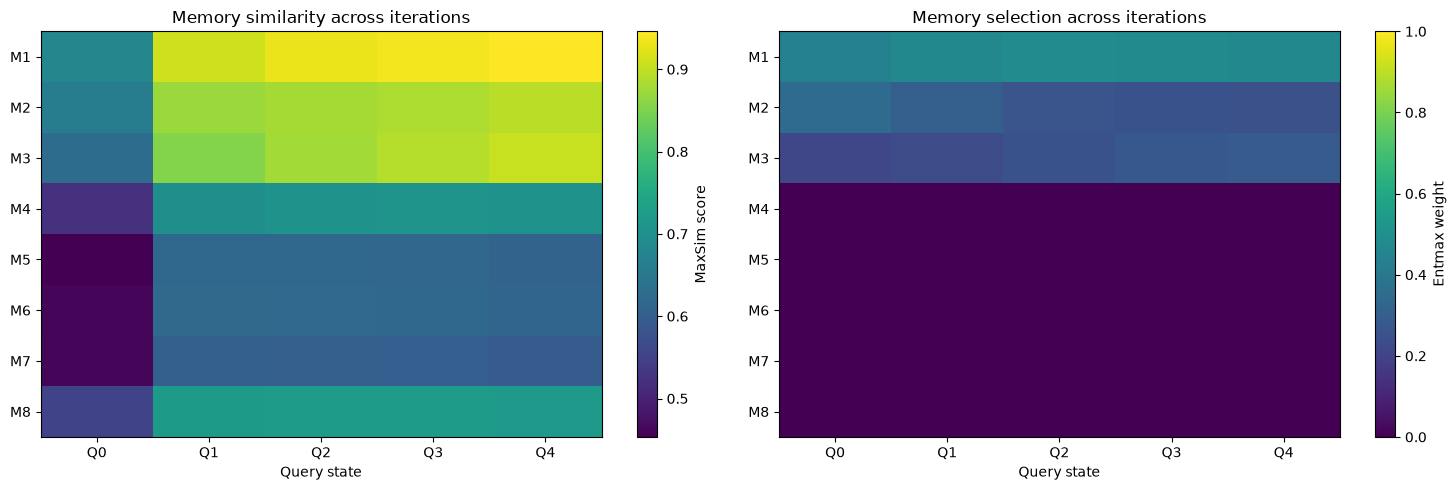

In [28]:

# ============================================================
# VISUALIZE RETRIEVAL DYNAMICS ACROSS HFY ITERATIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from entmax import entmax_bisect

@torch.no_grad()
def analyze_trajectory(
    trajectory,
    memories,
    memory_mask,
    alpha=1.85,
    beta=5.0,
):
    M = F.normalize(memories.float(), dim=-1)

    scores_history = []
    weights_history = []

    for state in trajectory:
        Q = F.normalize(state.float(), dim=-1)

        similarity = torch.matmul(
            Q,
            M.transpose(1, 2),
        )

        similarity = similarity.masked_fill(
            ~memory_mask[:, None, :],
            float("-inf"),
        )

        # MaxSim sentence scores
        scores = similarity.max(dim=-1).values.mean(dim=-1)

        # Sentence-level retrieval weights
        if alpha == 1.0:
            weights = F.softmax(beta * scores, dim=0)
        else:
            weights = entmax_bisect(
                beta * scores,
                alpha=alpha,
                dim=0,
                n_iter=100,
            )

        scores_history.append(scores.cpu().numpy())
        weights_history.append(weights.cpu().numpy())

    return (
        np.stack(scores_history),
        np.stack(weights_history),
    )


scores_history, weights_history = analyze_trajectory(
    trajectory,
    memories,
    memory_mask,
    alpha=ALPHA,
    beta=BETA,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

labels = [f"M{i+1}" for i in range(len(texts))]
iterations = [f"Q{k}" for k in range(len(trajectory))]

# MaxSim evolution
im1 = axes[0].imshow(
    scores_history.T,
    aspect="auto",
    cmap="viridis",
)

axes[0].set_title("Memory similarity across iterations")
axes[0].set_xticks(range(len(iterations)), iterations)
axes[0].set_yticks(range(len(labels)), labels)
axes[0].set_xlabel("Query state")
fig.colorbar(im1, ax=axes[0], label="MaxSim score")

# Entmax weights evolution
im2 = axes[1].imshow(
    weights_history.T,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1,
)

axes[1].set_title("Memory selection across iterations")
axes[1].set_xticks(range(len(iterations)), iterations)
axes[1].set_yticks(range(len(labels)), labels)
axes[1].set_xlabel("Query state")
fig.colorbar(im2, ax=axes[1], label="Entmax weight")

plt.tight_layout()
plt.show()


/var/folders/fw/kb_zk5_d30xgzynbrr15cky9vk9dby/T/ipykernel_32769/3224550860.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1], fontsize=14)


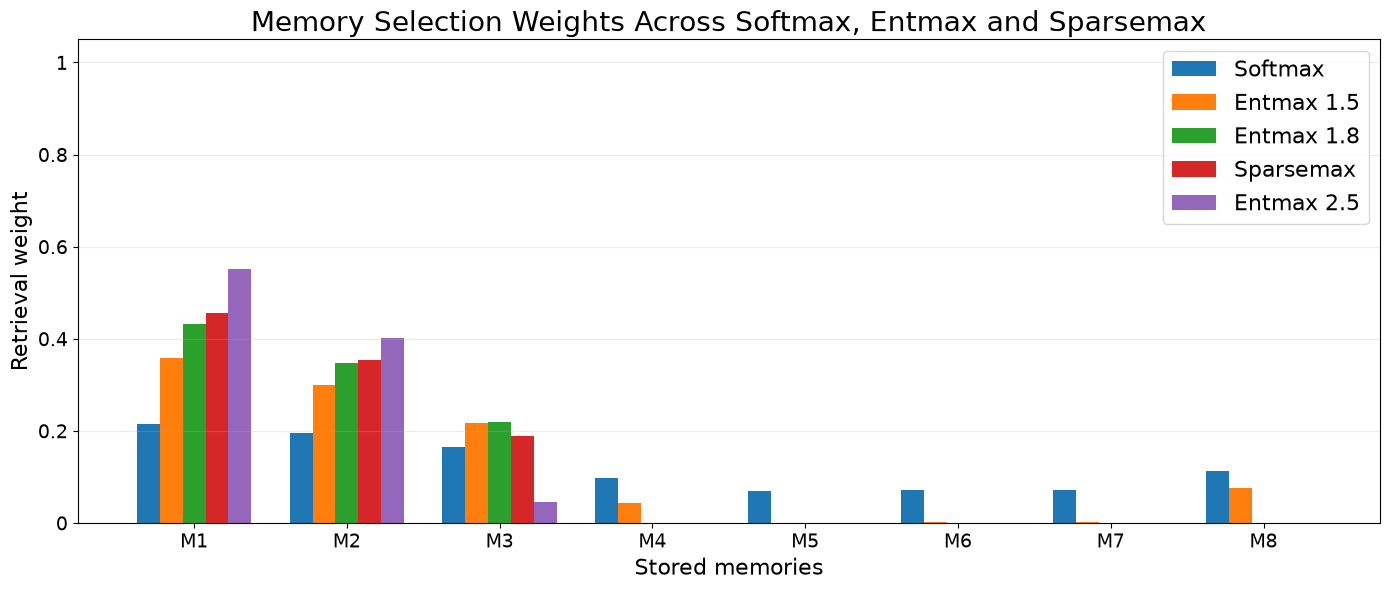

Memory            Softmax     Entmax 1.5     Entmax 1.8      Sparsemax     Entmax 2.5
M1                 0.2155         0.3585         0.4328         0.4569         0.5523
M2                 0.1943         0.2991         0.3469         0.3532         0.4019
M3                 0.1650         0.2165         0.2203         0.1899         0.0458
M4                 0.0985         0.0429         0.0000         0.0000         0.0000
M5                 0.0691         0.0009         0.0000         0.0000         0.0000
M6                 0.0718         0.0024         0.0000         0.0000         0.0000
M7                 0.0724         0.0029         0.0000         0.0000         0.0000
M8                 0.1133         0.0768         0.0000         0.0000         0.0000


In [26]:

# ============================================================
# 12. COMPARE MEMORY WEIGHTS: SOFTMAX / ENTMAX / SPARSEMAX
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from entmax import entmax_bisect

# ------------------------------------------------------------
# 1. Compute sentence-level MaxSim scores
# ------------------------------------------------------------

with torch.no_grad():
    Q = F.normalize(query.float(), dim=-1)
    M = F.normalize(memories.float(), dim=-1)

    # [N, Sq, Sm]
    similarity = torch.matmul(
        Q,
        M.transpose(1, 2),
    )

    similarity = similarity.masked_fill(
        ~memory_mask[:, None, :],
        float("-inf"),
    )

    # [N, Sq] -> [N]
    scores = similarity.max(dim=-1).values.mean(dim=-1)

# ------------------------------------------------------------
# 2. Compute weights for different alpha values
# ------------------------------------------------------------

alpha_configs = [
    ("Softmax", 1.0),
    ("Entmax 1.5", 1.5),
    ("Entmax 1.8", 1.8),
    ("Sparsemax", 2.0),
    ("Entmax 2.5", 2.5),
]

weights_by_method = {}

with torch.no_grad():
    for name, alpha in alpha_configs:
        logits = BETA * scores

        if alpha == 1.0:
            w = F.softmax(logits, dim=0)
        else:
            w = entmax_bisect(
                logits,
                alpha=alpha,
                dim=0,
                n_iter=100,
            )

        weights_by_method[name] = w.cpu().numpy()

# ------------------------------------------------------------
# 3. Grouped bar plot
# ------------------------------------------------------------

n_memories = memories.shape[0]
x = np.arange(n_memories)

bar_width = 0.15

fig, ax = plt.subplots(figsize=(14, 6))

for i, (name, _) in enumerate(alpha_configs):
    offset = (i - (len(alpha_configs) - 1) / 2) * bar_width

    ax.bar(
        x + offset,
        weights_by_method[name],
        width=bar_width,
        label=name,
    )

# set fontsize yticks
ax.set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1], fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(
    [f"M{i+1}" for i in range(n_memories)], fontsize=14
)

ax.set_xlabel("Stored memories", fontsize=16)
ax.set_ylabel("Retrieval weight", fontsize=16)
ax.set_title(
    "Memory Selection Weights Across "
    "Softmax, Entmax and Sparsemax", fontsize=20
)

ax.set_ylim(0, 1.05)
ax.legend(fontsize=16)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Print numerical weights
# ------------------------------------------------------------

print(f"{'Memory':<10}", end="")
for name, _ in alpha_configs:
    print(f"{name:>15}", end="")
print()

for j in range(n_memories):
    print(f"M{j+1:<9}", end="")
    for name, _ in alpha_configs:
        print(f"{weights_by_method[name][j]:>15.4f}", end="")
    print()
